# PCA on family centroids — do gene families separate from each other?

Same two feature tables and cleaning conventions as `pca_mechanism_exploration.ipynb`, but a different unit of analysis: instead of one point per **sequence** (colored by mechanism), this collapses each qualifying family to one point — its centroid — and asks how families relate to each other in feature space.

**Why this is a separate notebook rather than a mode of the mechanism one:** the mechanism notebook answers "do resistance mechanisms separate" (they don't well — silhouette 0.056). This answers a different question — "do individual gene families separate from each other" — and building it meant changing what a *sample* is, not just what a sample is colored by. Bolting both onto one notebook made it hard to tell which question a given cell was answering.

**Method, and why each step is in this specific order:**
1. Merge + clean exactly as in the mechanism notebook (same PDC/PRI fix folded in here too — the mechanism notebook predates that finding).
2. **Standardize at the sequence level first**, using all 6205 sequences — not per-family, not after collapsing to centroids. This keeps every family's centroid on the same scale, grounded in real population-level variance rather than re-derived from just a handful of family means.
3. **Then** collapse to one mean vector per family.
4. Restrict to families with **n≥10 sequences** before fitting PCA — not after. A centroid built from 1-2 sequences isn't an average of anything; it's just that sequence, unsmoothed, and it will look like an extreme outlier purely from having no noise to average out. Confirmed directly on this exact data: every one of the most "extreme" centroids in an unfiltered 395-family fit turned out to have n≤5.
5. **Re-fit PCA specifically on the n≥10 subset — do not fit on all 395 and then filter the scores.** The components themselves are shaped by whatever went into the fit; filtering afterward still leaves you with axes distorted by the noisy small-n centroids. This was a genuine bug caught by comparing the two approaches directly, not a stylistic preference.

In [2]:
!pip install adjustText

In [5]:
import colorsys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from adjustText import adjust_text

pd.set_option("display.width", 200)
print(f"pandas {pd.__version__}")

pandas 2.3.3


In [18]:
# --- inputs -- same two tables and paths as pca_mechanism_exploration.ipynb ---
PFEATURE_TABLE = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Genefamily/All_Family_ID_Relabeled_2/CD/test_seq/all_families_features.csv")
PROFET_TABLE   = Path("//home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Genefamily/All_Family_ID_Relabeled_2/CD/test_seq/all_families_profet_features.csv")

MIN_FAMILY_N = 10     # families below this can't support a reliable centroid -- see markdown
N_COMPONENTS = 20      # matches the validated 84-family fit this notebook replicates

OUTPUT_DIR = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/PCA_RESULTS")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
KEY = ["family", "sequence_id"]

In [19]:
pf = pd.read_csv(PFEATURE_TABLE)
pr = pd.read_csv(PROFET_TABLE)
print(f"Pfeature: {pf.shape[0]} rows x {pf.shape[1]-len(KEY)} features")
print(f"ProFET:   {pr.shape[0]} rows x {pr.shape[1]-len(KEY)} features")

merged = pf.merge(pr, on=KEY, how="inner", validate="one_to_one")
lost_pf, lost_pr = len(pf) - len(merged), len(pr) - len(merged)
print(f"\nMerged: {merged.shape[0]} rows x {merged.shape[1]-len(KEY)} features")
if lost_pf or lost_pr:
    print(f"  WARNING: {lost_pf} Pfeature row(s) and {lost_pr} ProFET row(s) had no counterpart and were dropped.")
else:
    print("  Both tables aligned exactly, no rows dropped.")

Pfeature: 237 rows x 976 features
ProFET:   237 rows x 40 features

Merged: 237 rows x 1016 features
  Both tables aligned exactly, no rows dropped.


In [20]:
meta_cols = list(KEY)
X_df = merged.drop(columns=meta_cols).select_dtypes(include=[np.number])
print(f"Starting matrix: {X_df.shape[0]} x {X_df.shape[1]}")

# Known issue (not present in the original mechanism notebook, added here): PDC beta-lactamase's
# PRI_* columns come from a systematic extraction failure, not real biology. Re-null before the
# generic imputation below so they don't silently look like real signal for that one family.
pri_cols = [c for c in X_df.columns if c.startswith("PRI_")]
if pri_cols and "PDC beta-lactamase" in merged["family"].values:
    mask = merged["family"] == "PDC beta-lactamase"
    X_df.loc[mask, pri_cols] = np.nan
    print(f"  re-nulled {len(pri_cols)} PRI_* columns for {mask.sum()} PDC beta-lactamase sequences")

all_nan = X_df.columns[X_df.isna().all()].tolist()
if all_nan:
    X_df = X_df.drop(columns=all_nan)
    print(f"  dropped {len(all_nan)} all-NaN column(s)")

n_nan = int(X_df.isna().sum().sum())
if n_nan:
    print(f"  imputing {n_nan} NaN cell(s) with column medians")
    X_df = X_df.fillna(X_df.median(numeric_only=True))

zero_var = X_df.columns[X_df.std(numeric_only=True) == 0].tolist()
if zero_var:
    X_df = X_df.drop(columns=zero_var)
    print(f"  dropped {len(zero_var)} zero-variance column(s)")

print(f"\nCleaned matrix: {X_df.shape}")

Starting matrix: 237 x 1016
  dropped 241 zero-variance column(s)

Cleaned matrix: (237, 775)


## Merging features

In [21]:

print(f"\nCleaned matrix: {X_df.shape}")

# 1. Re-attach the metadata columns (KEY) so you don't lose your target labels
# axis=1 stitches the dataframes side-by-side. 
# This works safely because the row order hasn't changed during the cleaning steps.
final_cleaned_df = pd.concat([merged[meta_cols], X_df], axis=1)

# 2. Define the output file path 
from pathlib import Path

# Adjust this path to wherever you want the final matrix to live
output_dir = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Genefamily/All_Family_ID_Relabeled_2/CD/test_seq")
output_dir.mkdir(parents=True, exist_ok=True) # Ensures the destination folder exists

output_file = output_dir / "cleaned_feature_matrix.csv"

# 3. Save the dataframe to a CSV file
# index=False prevents pandas from writing the internal row numbers as an extra unnamed column
final_cleaned_df.to_csv(output_file, index=False)

print(f"Successfully saved {final_cleaned_df.shape[0]} rows and {final_cleaned_df.shape[1]} columns to:")
print(f"-> {output_file}")


Cleaned matrix: (237, 775)
Successfully saved 237 rows and 777 columns to:
-> /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Genefamily/All_Family_ID_Relabeled_2/CD/test_seq/cleaned_feature_matrix.csv


In [9]:
# Standardize at the SEQUENCE level first (population-grounded scale), THEN collapse to family means.
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X_df.values), columns=X_df.columns, index=merged.index)
X_scaled["family"] = merged["family"].values

family_centroids = X_scaled.groupby("family").mean(numeric_only=True)
family_n = merged["family"].value_counts()
print(f"Family centroids (all families): {family_centroids.shape}")

reliable = family_n[family_n >= MIN_FAMILY_N].index
fc = family_centroids.loc[reliable]
fn = family_n.loc[reliable]
print(f"Restricted to n>={MIN_FAMILY_N}: {fc.shape[0]} families")

# One color per family, spaced via the golden angle so adjacent families in
# fc's order (descending by size) don't get similar hues. Deterministic,
# no external dependency, no ordering implied beyond "maximally distinguishable".
GOLDEN_ANGLE = 0.6180339887498949
hues = (np.arange(len(fc)) * GOLDEN_ANGLE) % 1.0
family_colors = [colorsys.hsv_to_rgb(h, 0.65, 0.85) for h in hues]
print(f"Assigned {len(family_colors)} distinct colors, one per family.")

Family centroids (all families): (396, 1038)
Restricted to n>=10: 84 families
Assigned 84 distinct colors, one per family.


84 families x 1038 features -> PCA (20 components)
PC1 10.2%  PC2 7.3%  PC1+PC2 17.5%
Components for 80% variance: 21 (of 20 computed; cumulative at 20: 65.8%)

NOTE: PC1+PC2 hold well under 30% of variance -- this is a genuinely high-dimensional
structure, not a 2-axis story. Don't over-read the 2D scatter's shape.


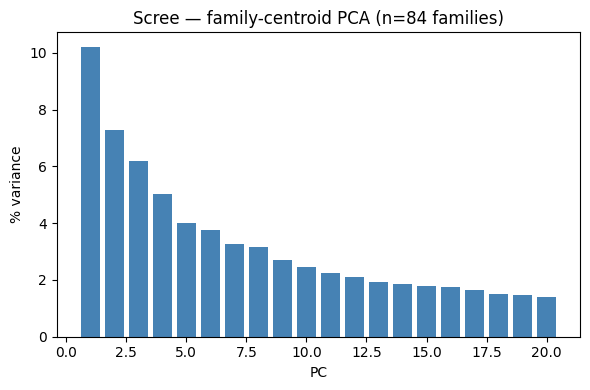

In [10]:
# Re-fit PCA fresh on ONLY the n>=10 centroids -- not filtered from a fit on all families.
n_comp = min(N_COMPONENTS, fc.shape[0] - 1, fc.shape[1])
pca = PCA(n_components=n_comp, random_state=0).fit(fc.values)
evr = pca.explained_variance_ratio_
scores = pca.transform(fc.values)

print(f"{fc.shape[0]} families x {fc.shape[1]} features -> PCA ({n_comp} components)")
print(f"PC1 {evr[0]*100:.1f}%  PC2 {evr[1]*100:.1f}%  PC1+PC2 {(evr[0]+evr[1])*100:.1f}%")
n80 = int(np.searchsorted(np.cumsum(evr), 0.80) + 1)
print(f"Components for 80% variance: {n80} (of {n_comp} computed; cumulative at {n_comp}: {np.cumsum(evr)[-1]*100:.1f}%)")
if (evr[0] + evr[1]) < 0.30:
    print("\nNOTE: PC1+PC2 hold well under 30% of variance -- this is a genuinely high-dimensional")
    print("structure, not a 2-axis story. Don't over-read the 2D scatter's shape.")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(1, len(evr) + 1), evr * 100, color="steelblue")
ax.set_xlabel("PC"); ax.set_ylabel("% variance")
ax.set_title(f"Scree — family-centroid PCA (n={fc.shape[0]} families)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "family_centroid_scree.png", dpi=150)
plt.show()

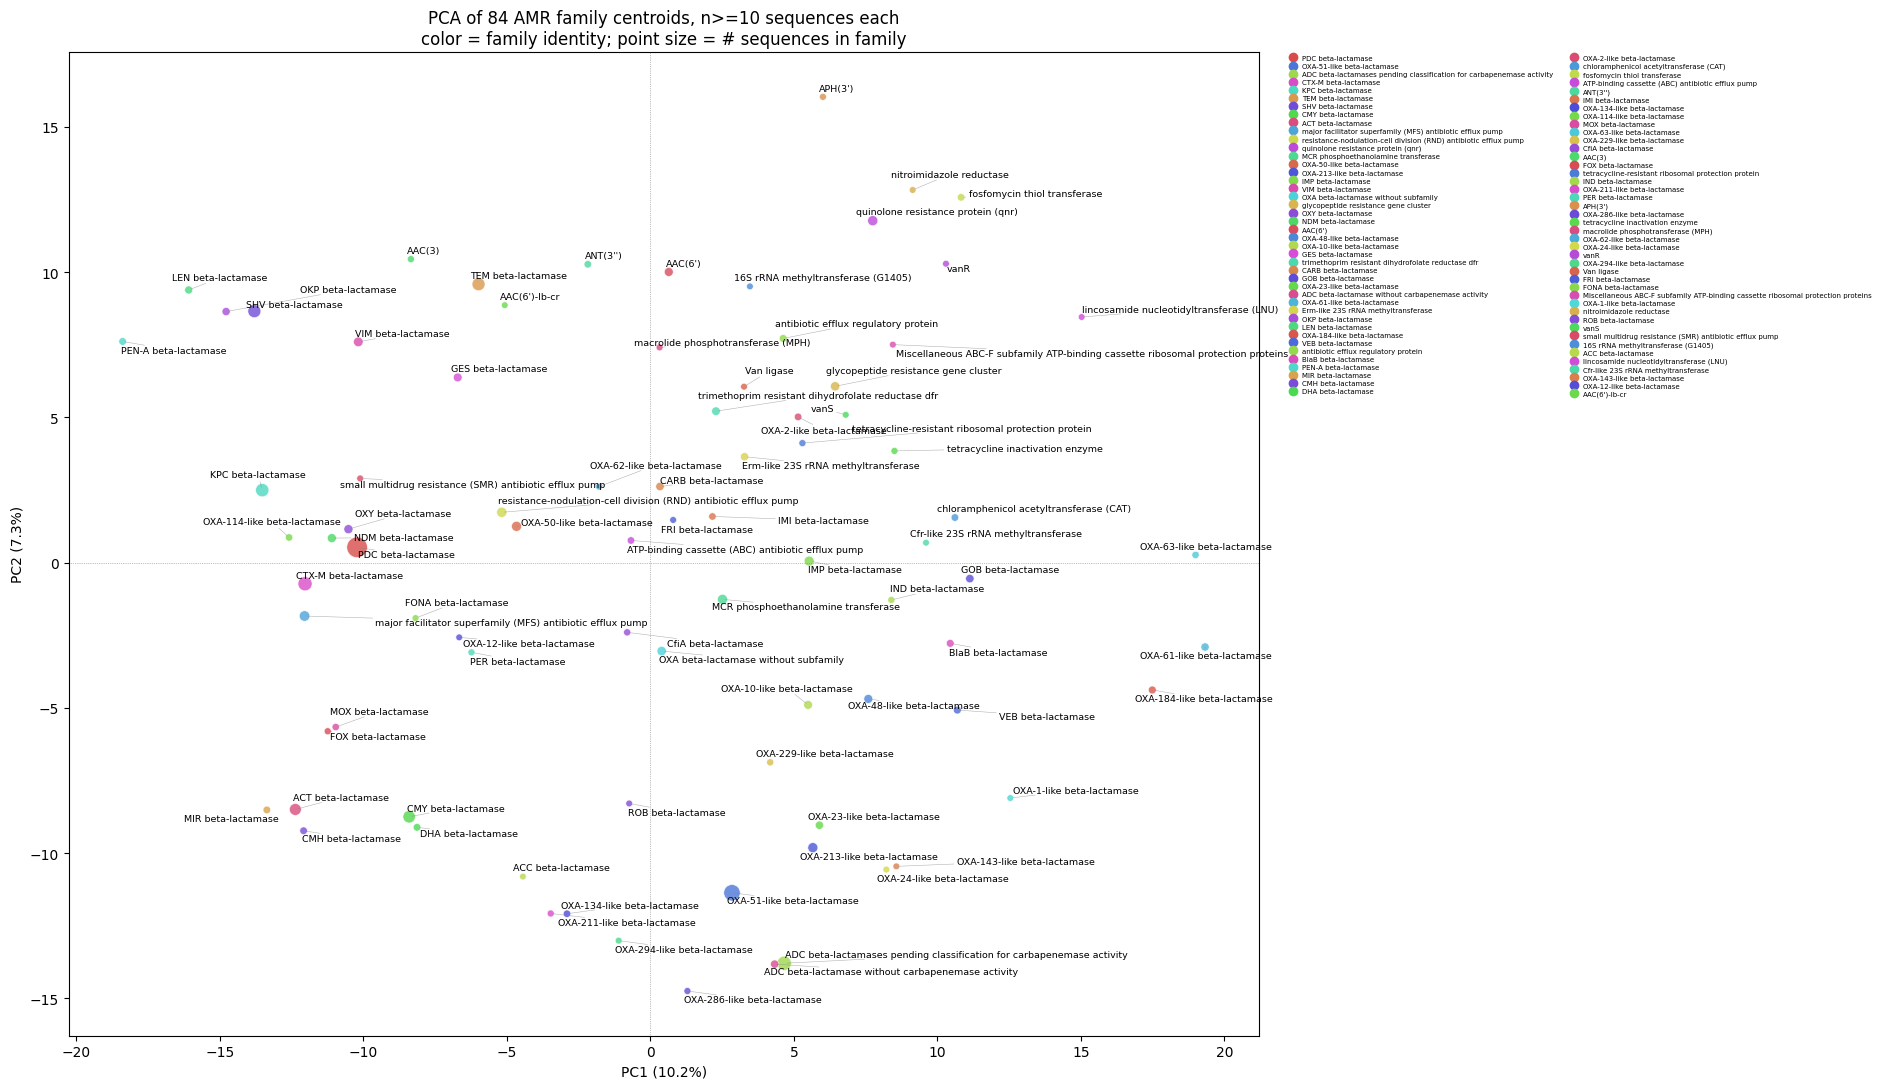

Scores (20 PCs) -> /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/PCA_RESULTS/family_centroid_scores.csv

Most extreme family centroids on the PC1/PC2 plot (largest 2D distance from origin):
                                  family  n_sequences        PC1       PC2 dominant_pc  dominant_pc_score
                    PEN-A beta-lactamase           35 -18.389540  7.609953         PC1         -18.389540
              OXA-61-like beta-lactamase           49  19.323595 -2.906046         PC1          19.323595
              OXA-63-like beta-lactamase           23  18.991339  0.261383         PC1          18.991339
                      LEN beta-lactamase           44 -16.087398  9.383004         PC1         -16.087398
             OXA-184-like beta-lactamase           39  17.485461 -4.384444         PC1          17.485461
lincosamide nucleotidyltransferase (LNU)           11  15.025765  8.451638         PC1          15.025765
                      OKP beta-lactamase           47 -1

In [13]:
sizes = 20 + 200 * (fn / fn.max())

fig, ax = plt.subplots(figsize=(19, 11))
ax.scatter(scores[:, 0], scores[:, 1], s=sizes.values, c=family_colors, alpha=0.8,
          edgecolors="white", linewidths=0.5)

legend_handles = [plt.Line2D([0], [0], marker='o', linestyle='', color=family_colors[i],
                             markersize=6, label=fc.index[i]) for i in range(len(fc))]
ax.legend(handles=legend_handles, fontsize=5, ncol=2, loc='upper left',
         bbox_to_anchor=(1.02, 1.0), borderaxespad=0., frameon=False,
         handletextpad=0.3, labelspacing=0.3)

texts = [ax.text(scores[i, 0], scores[i, 1], fc.index[i], fontsize=6.8) for i in range(len(fc))]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="grey", lw=0.4, alpha=0.6), expand=(1.3, 1.5))

ax.axhline(0, c="grey", lw=0.5, ls=":")
ax.axvline(0, c="grey", lw=0.5, ls=":")
ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
ax.set_title(f"PCA of {fc.shape[0]} AMR family centroids, n>={MIN_FAMILY_N} sequences each\n"
             f"color = family identity; point size = # sequences in family")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "family_centroid_pca_2.png", dpi=160, bbox_inches='tight')
plt.show()

pc_cols = [f"PC{i+1}" for i in range(n_comp)]
pc_data = {col: scores[:, i] for i, col in enumerate(pc_cols)}

# dist_from_origin stays 2D -- it's the distance ON THE PLOT ABOVE, unchanged in meaning.
dist = np.sqrt(scores[:, 0]**2 + scores[:, 1]**2)

# Which single PC (of all n_comp computed, not just PC1/PC2) is each family's identity
# MOST defined by. E.g. SMR efflux pump's real signal is on PC3 (+52), invisible if only
# PC1/PC2 are ever reported -- this is what makes the other 18 components visible at all.
dominant_idx = np.abs(scores).argmax(axis=1)
dominant_pc = [pc_cols[i] for i in dominant_idx]
dominant_pc_score = scores[np.arange(len(scores)), dominant_idx]

out = pd.DataFrame({
    "family": fc.index, "n_sequences": fn.values,
    **pc_data,
    "dist_from_origin": dist,
    "dominant_pc": dominant_pc,
    "dominant_pc_score": dominant_pc_score,
})
out = out.sort_values("dist_from_origin", ascending=False)
out.to_csv(OUTPUT_DIR / "family_centroid_scores_2.csv", index=False)

print(f"Scores ({n_comp} PCs) -> {OUTPUT_DIR/'family_centroid_scores.csv'}")
print("\nMost extreme family centroids on the PC1/PC2 plot (largest 2D distance from origin):")
print(out.head(10)[["family", "n_sequences", "PC1", "PC2", "dominant_pc", "dominant_pc_score"]].to_string(index=False))
print("\nHow many families each PC is the dominant axis for:")
print(pd.Series(dominant_pc).value_counts().reindex(pc_cols).fillna(0).astype(int).to_string())

In [14]:
pc_cols = [f"PC{i+1}" for i in range(n_comp)]
loadings = pd.DataFrame(pca.components_.T, index=fc.columns, columns=pc_cols)
for pc in pc_cols:
    print(f"\nTop 12 loadings on {pc}:")
    top = loadings[pc].abs().sort_values(ascending=False).head(12)
    for feat in top.index:
        print(f"   {loadings.loc[feat, pc]:+.3f}  {feat}")

loadings.to_csv(OUTPUT_DIR / "family_centroid_loadings_2.csv")
print(f"\nFull loadings -> {OUTPUT_DIR/'family_centroid_loadings_2.csv'}")


Top 12 loadings on PC1:
   +0.094  PCP_Z2
   -0.093  PCP_AL
   -0.089  QSO1_SC_A
   -0.087  SEP_AL
   -0.086  SEP_TN
   -0.086  PCP_NP
   +0.086  SER_A
   -0.086  APAAC1_A
   -0.086  PAAC1_A
   -0.086  AAC_A
   -0.085  PCP_TN
   -0.085  PCP_SM

Top 12 loadings on PC2:
   +0.099  PCP_AC
   +0.099  PCP_NC
   -0.095  QSO1_SC_Q
   +0.093  SEP_NC
   +0.093  SEP_AC
   -0.089  APAAC1_Q
   -0.089  PAAC1_Q
   -0.089  AAC_Q
   +0.086  PAAC1_D
   +0.086  APAAC1_D
   +0.086  AAC_D
   -0.085  isoelectric_point

Top 12 loadings on PC3:
   +0.219  PRI_AC
   +0.219  PRI_NC
   +0.179  PRI_NE
   +0.179  PRI_NE_pH
   +0.167  PRI_BS
   +0.167  PRI_PC
   +0.156  PRI_SA_EX
   +0.152  PRI_HL
   +0.143  PRI_NP
   -0.137  QSO1_SC1
   -0.137  QSO1_G1
   +0.136  PRI_SA_BU

Top 12 loadings on PC4:
   +0.107  CTC_615
   +0.103  DPC1_GW
   +0.100  CTC_416
   +0.093  PAAC1_lam1
   -0.091  PCP_SA_IN
   -0.089  SEP_SA_IN
   +0.088  PCP_SS_HE
   -0.088  PCP_HX
   -0.087  SEP_HX
   +0.087  SEP_SS_HE
   +0.086  CTC_155


## Cosine similarity among each PC's dominant-family group

For each PC, its "members" are the families whose `dominant_pc` (largest |score| out of all 20 computed PCs) is that PC -- e.g. PC3's 4 members, or PC9's lone member CfiA beta-lactamase. This asks: within each such group, how similar are the member families actually to each other?

Similarity is computed on each family's **full 20-PC score vector** (`PC1..PC20`), the same space `dominant_pc` itself was derived from -- not the raw 1038-dim feature centroid. A group of size <2 has no pair to compare, so its row is `NaN` by construction, not missing data.

Fully self-contained: reads `family_centroid_scores_2.csv` fresh from disk, no dependency on any variable from earlier cells.

One naming note on that input file, so it isn't a mystery later: the section above originally wrote `family_centroid_scores.csv`, but was manually edited afterward to write `family_centroid_scores_2.csv` instead (keeping the 20-PC output alongside the earlier PC1/PC2-only file rather than overwriting it). That edit only updated the `.to_csv(...)` call -- the cell's own printed confirmation message still says the old filename without `_2`. The real file being written is `family_centroid_scores_2.csv`, which is what this section reads.

**Headline finding, not assumed going in**: sharing a dominant PC does not imply the group's families are actually similar. PC1 -- the *largest* group at 24 families -- has a mean pairwise cosine similarity of only **0.017** (essentially orthogonal on average). PC5's group of just 3 families, by contrast, is tightly clustered at **0.538**.

In [15]:
FAMILY_CENTROID_SCORES_CSV = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/PCA_RESULTS/family_centroid_scores_2.csv")
PC_COSINE_SIMILARITY_CSV = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/PCA_RESULTS/family_dominant_pc_cosine_similarity.csv")

from sklearn.metrics.pairwise import cosine_similarity

scores_full = pd.read_csv(FAMILY_CENTROID_SCORES_CSV)
pc_cols = [c for c in scores_full.columns if c.startswith("PC") and c[2:].isdigit()]
scores_by_family = scores_full.set_index("family")[pc_cols]
dominant_pc_by_family = scores_full.set_index("family")["dominant_pc"]

rows = []
for pc in pc_cols:
    members = dominant_pc_by_family[dominant_pc_by_family == pc].index.tolist()
    n = len(members)
    if n < 2:
        rows.append({"PC": pc, "n_members": n, "mean_cos": np.nan, "min_cos": np.nan,
                    "max_cos": np.nan, "members": ", ".join(members)})
        continue
    vecs = scores_by_family.loc[members].values
    sim = cosine_similarity(vecs)
    iu = np.triu_indices(n, k=1)   # off-diagonal, upper triangle -- excludes self-similarity (always 1.0)
    pair_sims = sim[iu]
    rows.append({"PC": pc, "n_members": n, "mean_cos": pair_sims.mean(),
                "min_cos": pair_sims.min(), "max_cos": pair_sims.max(),
                "members": ", ".join(members)})

pc_cosine_summary = pd.DataFrame(rows)
pc_cosine_summary.to_csv(PC_COSINE_SIMILARITY_CSV, index=False)

print(f"Loaded {len(scores_full)} families x {len(pc_cols)} PCs from {FAMILY_CENTROID_SCORES_CSV}")
print(f"-> {PC_COSINE_SIMILARITY_CSV}")
print(pc_cosine_summary.drop(columns="members").to_string(index=False))
print("\nMembers per PC (only groups with >=2):")
for _, row in pc_cosine_summary[pc_cosine_summary["n_members"] >= 2].iterrows():
    print(f"  {row['PC']} (mean cos {row['mean_cos']:.3f}): {row['members']}")

Loaded 84 families x 20 PCs from /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/PCA_RESULTS/family_centroid_scores_2.csv
-> /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/PCA_RESULTS/family_dominant_pc_cosine_similarity.csv
  PC  n_members  mean_cos   min_cos   max_cos
 PC1         24  0.016744 -0.597439  0.994281
 PC2         20  0.023898 -0.714938  0.999781
 PC3          4  0.000546 -0.582788  0.702844
 PC4          7  0.100702 -0.729697  0.703376
 PC5          3  0.538390  0.478513  0.641043
 PC6          5  0.241435 -0.192155  0.860947
 PC7          2 -0.020471 -0.020471 -0.020471
 PC8          6  0.331164 -0.444130  0.767170
 PC9          1       NaN       NaN       NaN
PC10          2 -0.124576 -0.124576 -0.124576
PC11          3  0.058075 -0.149300  0.260920
PC12          2 -0.165960 -0.165960 -0.165960
PC13          1       NaN       NaN       NaN
PC14          0       NaN       NaN       NaN
PC15          3 -0.188624 -0.331370  0.090077
PC16          0   

## Per-PC feature contributions: loadings x family-discrimination F-statistic

PCA loadings show which features build a PC's *variance* -- but PCA is unsupervised, it has no idea "family" is even a label. That's a different question from "which features actually help tell families apart," which is what an ANOVA F-test answers directly (`sklearn.feature_selection.f_classif`, family as the class): for each feature, how much does it differ *between* families relative to how much it varies *within* one.

This merges the two: for each PC, its top 20 loading-defined features, each annotated with that same feature's family-discrimination F-statistic. The F-statistic is per-*feature*, computed once globally (not per PC) -- if a feature happens to load highly on more than one PC, the same F-statistic value appears on each of those rows.

**Headline finding this makes visible PC-by-PC**: PC1's top loading feature, `PCP_Z2`, has F-statistic 290.68 -- real, but nowhere close to the strongest family-discriminator in the whole dataset, `CTC_762` (F=1266.28, 4.4x higher), whose own strongest loading anywhere is a mere 0.10 on PC7. The features building the highest-variance axes are not the features doing the most work separating families -- this table lets you check that PC-by-PC instead of just for PC1/PC2.

Fully self-contained. Loadings are read from `family_centroid_loadings_2.csv` (already on disk). The F-statistic has never been saved anywhere -- it only existed as an ad-hoc calculation -- so it's recomputed here from the two raw feature tables, redoing the same cleaning pipeline (PDC `PRI_*` re-null, drop all-NaN, median-impute, drop zero-variance, standardize) used throughout this notebook. No dependency on any variable from any other cell.

In [16]:
PFEATURE_TABLE = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/card-data/refined_details/Final_Results/pfeatures/all_families_features.csv")
PROFET_TABLE = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/card-data/refined_details/Final_Results/profet_features/all_families_profet_features.csv")
FAMILY_CENTROID_LOADINGS_CSV = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/PCA_RESULTS/family_centroid_loadings_2.csv")
PC_FEATURE_CONTRIBUTIONS_CSV = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/PCA_RESULTS/pc_feature_contributions_top20.csv")

TOP_N_PER_PC = 20
MIN_FAMILY_N = 10
KEY = ["family", "sequence_id"]

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif

pf = pd.read_csv(PFEATURE_TABLE)
pr = pd.read_csv(PROFET_TABLE)
merged = pf.merge(pr, on=KEY, how="inner", validate="one_to_one")

X_df = merged.drop(columns=KEY).select_dtypes(include=[np.number])
pri_cols = [c for c in X_df.columns if c.startswith("PRI_")]
if pri_cols and "PDC beta-lactamase" in merged["family"].values:
    X_df.loc[merged["family"] == "PDC beta-lactamase", pri_cols] = np.nan
X_df = X_df.drop(columns=X_df.columns[X_df.isna().all()].tolist())
X_df = X_df.fillna(X_df.median(numeric_only=True))
X_df = X_df.drop(columns=X_df.columns[X_df.std(numeric_only=True) == 0].tolist())

X_scaled = StandardScaler().fit_transform(X_df.values)

family_counts = merged["family"].value_counts()
reliable_families = family_counts[family_counts >= MIN_FAMILY_N].index
seq_mask = merged["family"].isin(reliable_families).values

F_stat, p_value = f_classif(X_scaled[seq_mask], merged.loc[seq_mask, "family"].values)
f_test_by_feature = pd.Series(F_stat, index=X_df.columns)
p_value_by_feature = pd.Series(p_value, index=X_df.columns)

print(f"{seq_mask.sum()} sequences from {len(reliable_families)} families -> "
      f"F-test computed for {len(f_test_by_feature)} features")

5479 sequences from 84 families -> F-test computed for 1038 features


In [17]:
loadings = pd.read_csv(FAMILY_CENTROID_LOADINGS_CSV, index_col=0)
pc_cols = list(loadings.columns)
print(f"Loaded loadings: {loadings.shape[0]} features x {loadings.shape[1]} PCs from {FAMILY_CENTROID_LOADINGS_CSV}")

rows = []
for pc in pc_cols:
    pc_loadings = loadings[pc]
    top_features = pc_loadings.abs().sort_values(ascending=False).head(TOP_N_PER_PC).index
    for feat in top_features:
        rows.append({
            "PC": pc,
            "feature": feat,
            "loading": pc_loadings[feat],
            "abs_loading": abs(pc_loadings[feat]),
            "F_statistic": f_test_by_feature.get(feat, np.nan),
            "p_value": p_value_by_feature.get(feat, np.nan),
        })

pc_feature_contributions = pd.DataFrame(rows)
pc_feature_contributions.to_csv(PC_FEATURE_CONTRIBUTIONS_CSV, index=False)

print(f"-> {PC_FEATURE_CONTRIBUTIONS_CSV}  ({len(pc_feature_contributions)} rows = "
      f"{len(pc_cols)} PCs x top {TOP_N_PER_PC})")
print(pc_feature_contributions.head(10).to_string(index=False))

# how many of each PC's top-20 loading features are ALSO among the global top-20 F-stat features?
global_top20_fstat = set(f_test_by_feature.sort_values(ascending=False).head(20).index)
overlap_per_pc = pc_feature_contributions.groupby("PC")["feature"].apply(
    lambda s: len(set(s) & global_top20_fstat))
print("\nHow many of each PC's top-20 loading features are ALSO in the global top-20 F-stat features:")
print(overlap_per_pc.reindex(pc_cols).to_string())

Loaded loadings: 1038 features x 20 PCs from /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/PCA_RESULTS/family_centroid_loadings_2.csv
-> /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/PCA_RESULTS/pc_feature_contributions_top20.csv  (400 rows = 20 PCs x top 20)
 PC   feature   loading  abs_loading  F_statistic  p_value
PC1    PCP_Z2  0.093892     0.093892   290.680497      0.0
PC1    PCP_AL -0.093193     0.093193   307.299426      0.0
PC1 QSO1_SC_A -0.089233     0.089233   317.015154      0.0
PC1    SEP_AL -0.086628     0.086628   218.321786      0.0
PC1    SEP_TN -0.086113     0.086113   234.040722      0.0
PC1    PCP_NP -0.085998     0.085998   214.884290      0.0
PC1     SER_A  0.085691     0.085691   255.769781      0.0
PC1  APAAC1_A -0.085513     0.085513   297.135665      0.0
PC1   PAAC1_A -0.085513     0.085513   297.135665      0.0
PC1     AAC_A -0.085513     0.085513   297.135665      0.0

How many of each PC's top-20 loading features are ALSO in the glob